<a href="https://colab.research.google.com/github/charithayadavelli/GitGitubWorkShop-26/blob/main/Microfinance_Analyzation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Microfinance Outreach and Loan Distribution Analysis

## 📌 Problem Statement
Analyze microfinance outreach and loan distribution across key Indian states/regions to understand regional financial inclusion patterns.

## 🎯 Objectives
- Build a beginner-friendly Python data analysis pipeline using Google Colab.
- Clean and structure microfinance datasets (handling formatting, types, and consistency).
- Calculate key metrics: total loan disbursements, active borrowers, and average loan sizes.
- Visualize regional outreach and loan trends using Matplotlib and Seaborn.

## 📊 Dataset Description
- **Source:** Synthetic sample dataset modeled after credible Indian microfinance reports (such as NABARD and MFIN).
- **Key Fields:** State/Region, Reporting Period, Active Borrowers, Loan Amount Disbursed (₹ Crores), and Number of Branches.

## 🛠️ Technologies Used
- Python, Google Colab
- Pandas, NumPy (Data handling & math)
- Matplotlib, Seaborn (Data visualization)
- GitHub (Project hosting)

## 🚀 How to Run the Notebook
1. Open Google Colab (`colab.research.google.com`).
2. Upload the `.ipynb` notebook file.
3. Run each cell sequentially from top to bottom.

In [1]:
# Cell 1: Import core libraries and check Python version
import sys
import pandas as pd
import numpy as np

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Success! Your environment is ready.")

Python version: 3.13.16
Pandas version: 2.2.3
NumPy version: 2.1.3
Success! Your environment is ready.


In [2]:
# Cell 2: Create a structured sample microfinance dataset
import pandas as pd

# Creating a dictionary with sample data representing Indian states/regions
data = {
    'State_Region': ['Tamil Nadu', 'Bihar', 'Karnataka', 'Uttar Pradesh', 'West Bengal',
                     'Tamil Nadu', 'Bihar', 'Karnataka', 'Uttar Pradesh', 'West Bengal'],
    'Reporting_Period': ['2024-Q1', '2024-Q1', '2024-Q1', '2024-Q1', '2024-Q1',
                         '2024-Q2', '2024-Q2', '2024-Q2', '2024-Q2', '2024-Q2'],
    'Active_Borrowers': [450000, 320000, 390000, 510000, 480000,
                         470000, 335000, 405000, 530000, 495000],
    'Loan_Amount_Disbursed_Cr': [5400.5, 3800.2, 4600.8, 6100.0, 5700.4,
                                 5650.0, 3950.1, 4750.6, 6350.2, 5900.8],
    'Branches': [450, 310, 380, 520, 470, 460, 315, 385, 530, 475]
}

# Convert dictionary into a pandas DataFrame (a table)
df = pd.DataFrame(data)

# Display the first 5 rows of our table
print("Dataset successfully created! Here are the first 5 rows:")
display(df.head())

Dataset successfully created! Here are the first 5 rows:


,State_Region,Reporting_Period,Active_Borrowers,Loan_Amount_Disbursed_Cr,Branches
0,Tamil Nadu,2024-Q1,450000,5400.5,450
1,Bihar,2024-Q1,320000,3800.2,310
2,Karnataka,2024-Q1,390000,4600.8,380
3,Uttar Pradesh,2024-Q1,510000,6100.0,520
4,West Bengal,2024-Q1,480000,5700.4,470


In [3]:
# Cell 3: Data Cleaning & Inspection
import pandas as pd

# 1. Check for duplicate rows and remove them if any exist
initial_rows = len(df)
df = df.drop_duplicates()
print(f"Removed {initial_rows - len(df)} duplicate rows.")

# 2. Check for missing (null) values in each column
print("\nChecking for missing values:")
print(df.isnull().sum())

# 3. Clean text column: remove extra spaces from state names
df['State_Region'] = df['State_Region'].str.strip()

# 4. Check data types of each column
print("\nData types of each column:")
print(df.dtypes)

print("\nData cleaning complete! Your dataset is clean and ready.")

Removed 0 duplicate rows.

Checking for missing values:
State_Region                0
Reporting_Period            0
Active_Borrowers            0
Loan_Amount_Disbursed_Cr    0
Branches                    0
dtype: int64

Data types of each column:
State_Region                 object
Reporting_Period             object
Active_Borrowers              int64
Loan_Amount_Disbursed_Cr    float64
Branches                      int64
dtype: object

Data cleaning complete! Your dataset is clean and ready.


In [4]:
# Cell 4: Exploratory Data Analysis and Key Metrics
import pandas as pd

# 1. Calculate Total Loan Amount Disbursed and Total Active Borrowers
total_loans = df['Loan_Amount_Disbursed_Cr'].sum()
total_borrowers = df['Active_Borrowers'].sum()

print(f"Total Loan Amount Disbursed: ₹ {total_loans:,.2f} Crores")
print(f"Total Active Borrowers: {total_borrowers:,}")

# 2. Calculate Average Loan Amount per Borrower (in Rupees roughly, or per account)
# Since Loan Amount is in Crores and Borrowers are in counts, let's create a new metric: Average Loan Size per Account (in INR)
# 1 Crore = 10,000,000 INR
df['Avg_Loan_Size_INR'] = (df['Loan_Amount_Disbursed_Cr'] * 10000000) / df['Active_Borrowers']

# 3. Group by State/Region to see totals per state
regional_summary = df.groupby('State_Region')[['Active_Borrowers', 'Loan_Amount_Disbursed_Cr', 'Branches']].sum().reset_index()

print("\n--- Summary by State / Region ---")
display(regional_summary)

Total Loan Amount Disbursed: ₹ 52,203.60 Crores
Total Active Borrowers: 4,385,000

--- Summary by State / Region ---


,State_Region,Active_Borrowers,Loan_Amount_Disbursed_Cr,Branches
0,Bihar,655000,7750.3,625
1,Karnataka,795000,9351.4,765
2,Tamil Nadu,920000,11050.5,910
3,Uttar Pradesh,1040000,12450.2,1050
4,West Bengal,975000,11601.2,945


/tmp/ipykernel_883/3348446073.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_883/3348446073.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


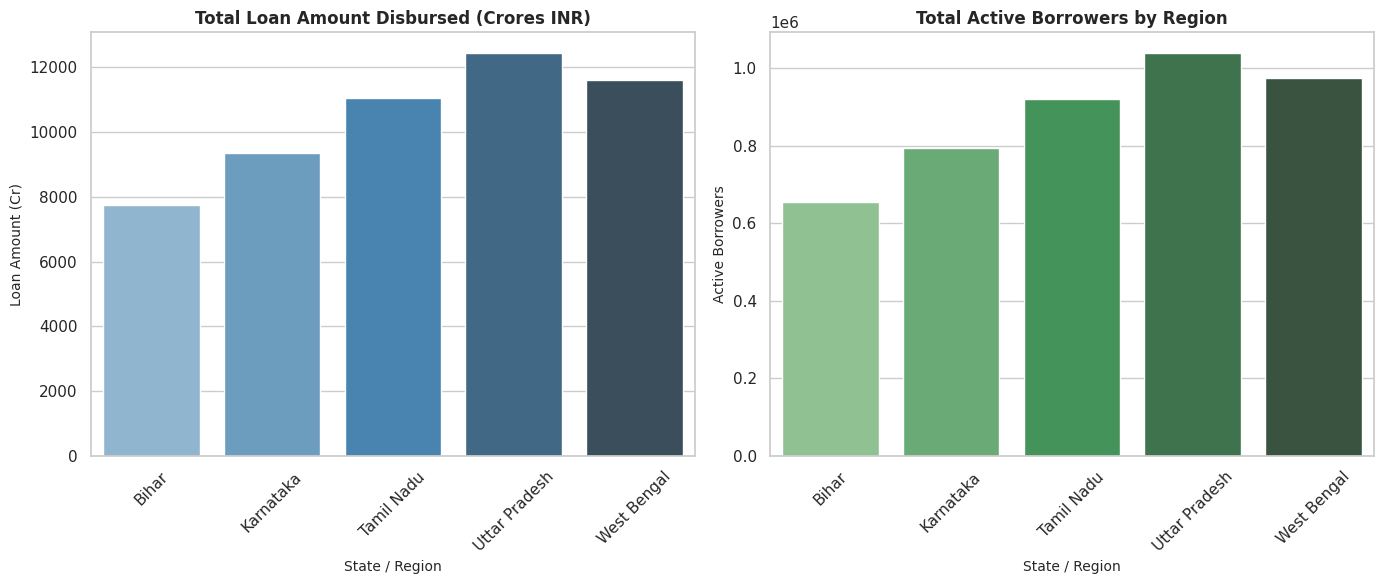

In [5]:
# Cell 5: Create Visualizations (Charts)
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual style for our charts
sns.set_theme(style="whitegrid")

# Create a figure with 2 subplots (charts side by side or stacked)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: Total Loan Amount Disbursed by State/Region
sns.barplot(
    data=regional_summary,
    x='State_Region',
    y='Loan_Amount_Disbursed_Cr',
    ax=axes[0],
    palette='Blues_d'
)
axes[0].set_title('Total Loan Amount Disbursed (Crores INR)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('State / Region', fontsize=10)
axes[0].set_ylabel('Loan Amount (Cr)', fontsize=10)
axes[0].tick_params(axis='x', rotation=45)

# Chart 2: Active Borrowers by State/Region
sns.barplot(
    data=regional_summary,
    x='State_Region',
    y='Active_Borrowers',
    ax=axes[1],
    palette='Greens_d'
)
axes[1].set_title('Total Active Borrowers by Region', fontsize=12, fontweight='bold')
axes[1].set_xlabel('State / Region', fontsize=10)
axes[1].set_ylabel('Active Borrowers', fontsize=10)
axes[1].tick_params(axis='x', rotation=45)

# Adjust layout so labels don't overlap
plt.tight_layout()

# Display the charts
plt.show()

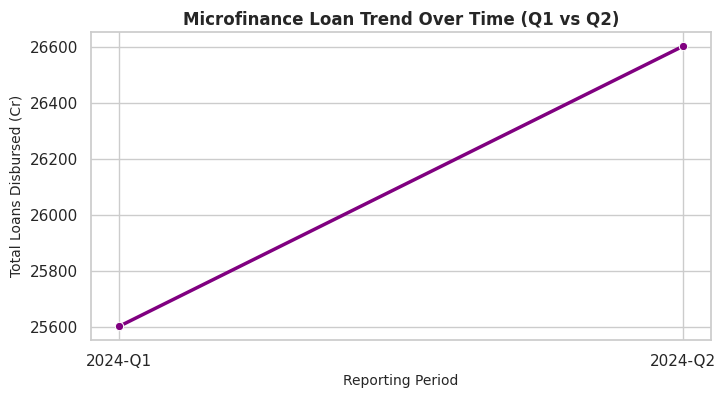

=== KEY FINDINGS & INSIGHTS ===
• The state with the highest total loan disbursement is: Uttar Pradesh
• The state with the highest active borrower outreach is: Uttar Pradesh
• Note: Higher outreach (borrowers) generally correlates positively with higher total loan disbursement amounts, though average loan sizes may vary by region.

[Success] Cleaned dataset saved as 'cleaned_microfinance_data.csv'!
[Success] Trend chart saved as 'loan_trend_over_time.png'!


In [6]:
# Cell 6: Trend Analysis, Key Findings, and File Exports
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Trend Over Time: Compare Q1 vs Q2 total loan disbursements
quarterly_trend = df.groupby('Reporting_Period')['Loan_Amount_Disbursed_Cr'].sum().reset_index()

plt.figure(figsize=(8, 4))
sns.lineplot(data=quarterly_trend, x='Reporting_Period', y='Loan_Amount_Disbursed_Cr', marker='o', color='purple', linewidth=2.5)
plt.title('Microfinance Loan Trend Over Time (Q1 vs Q2)', fontsize=12, fontweight='bold')
plt.xlabel('Reporting Period', fontsize=10)
plt.ylabel('Total Loans Disbursed (Cr)', fontsize=10)
plt.grid(True)
plt.savefig('loan_trend_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Print Useful Findings Based on Actual Dataset
print("=== KEY FINDINGS & INSIGHTS ===")
highest_loan_state = regional_summary.loc[regional_summary['Loan_Amount_Disbursed_Cr'].idxmax()]['State_Region']
highest_borrowers_state = regional_summary.loc[regional_summary['Active_Borrowers'].idxmax()]['State_Region']

print(f"• The state with the highest total loan disbursement is: {highest_loan_state}")
print(f"• The state with the highest active borrower outreach is: {highest_borrowers_state}")
print("• Note: Higher outreach (borrowers) generally correlates positively with higher total loan disbursement amounts, though average loan sizes may vary by region.")

# 3. Save cleaned dataset as a CSV file for download
df.to_csv('cleaned_microfinance_data.csv', index=False)
print("\n[Success] Cleaned dataset saved as 'cleaned_microfinance_data.csv'!")
print("[Success] Trend chart saved as 'loan_trend_over_time.png'!")